# MD-EXAFS from a trajectory: a worked example with iron

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nmarcella/feffGPU/blob/main/tutorials/01_md_exafs_iron.ipynb)

MD-EXAFS computes the EXAFS spectrum of a molecular dynamics trajectory. For every frame it computes the spectrum
of each absorbing atom from the actual positions of its neighbors, and then it averages over the atoms and the
frames. No Debye-Waller factor is put in by hand: the disorder is in the frames.

This notebook goes through one complete example with `feffgpu`:

1. install the package and check the GPU
2. look at the trajectory
3. write the configuration
4. run
5. read the averaged spectrum and its parts
6. check that enough frames were used
7. connect the spectrum to the structure
8. compare with a "measured" spectrum

**The data are synthetic.** The trajectory holds 60 frames of 128 iron atoms in a bcc block. It was made by
[`tutorials/make_fe_trajectory.py`](https://github.com/nmarcella/feffGPU/blob/main/tutorials/make_fe_trajectory.py) with springs between neighbors and a
thermostat at 300 K. The forces are not a model of iron; the file only has the features of a real trajectory. The
spectrum it is compared with in step 8 is synthetic too. Nothing in this notebook was measured.

**Time.** About one minute of computing on the 12 GB GPU used for development. Colab's free GPU is slower, and the
notebook has not been timed there.

**On Colab, choose a GPU first:** menu *Runtime → Change runtime type → T4 GPU*. Then run the cells from the top.

## 1. Install and check

On Colab, the next cell downloads the repository (about 100 MB, most of it the table of free atoms that the
potentials start from) and installs the package. On your own computer the cell installs nothing: install `feffgpu`
first (`pip install -e .` in a checkout of the repository) and start Jupyter in the `tutorials` folder.

In [1]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and not Path("feffGPU").exists():
    !git clone --depth 1 https://github.com/nmarcella/feffGPU.git
    !pip install -q ./feffGPU
REPO = Path("feffGPU") if IN_COLAB else Path("..")    # the checkout of the repository

`feffgpu doctor` reports the GPU, the versions, and whether the package's compiled GPU routines pass their test on
this machine.

In [2]:
!feffgpu doctor

feffgpu 0.2.0, Python 3.12.3, PyTorch 2.14.1+cu126 (CUDA build 12.6)
  GPU 0: NVIDIA GeForce RTX 3080 Ti, 11.24 of 11.63 GB free
  GPU kernels of the radial solver: in use (Triton 3.8.0, a version they were tested with); they reproduce the plain code to 4e-14
  free-atom table: 99 element files in .../src/feffgpu/data/atoms
  FEFF 8.5L library (optional): not found (optional; needed only for ION / UNFREEZEF cards, rebuilding the free-atom table, and the oracle tests (fortran/README.md))
  packages: numpy 2.5.4, scipy 1.18.1, ase 3.29.0, h5py 3.16.0, pydantic 2.14.3, matplotlib 3.11.2, larch 2026.3.1, mcp installed
  not installed: MDAnalysis: not installed (optional: pip install 'feffgpu[mda]'); mace: not installed (optional: pip install 'feffgpu[mace]')
OK


The last line must be `OK`.

- **No GPU in the report:** on Colab, choose the GPU runtime (top of this notebook) and run the cells again. The
  package also runs on a CPU, slowly: set `devices = "cpu"` in the configuration below.
- **The line about the GPU kernels reports a failed test:** follow the instruction it prints. It names the setting
  `FEFFGPU_KERNELS=0`, which selects the slower plain code; in a notebook that is a cell with `%env FEFFGPU_KERNELS=0`.

## 2. The trajectory

A trajectory for MD-EXAFS is a file with the element and the position of every atom in every frame, and the
periodic cell. Extended xyz, LAMMPS text dumps, VASP XDATCAR, CP2K xyz and ASE trajectories are read as they are
([Trajectories](https://github.com/nmarcella/feffGPU/blob/main/docs/md/trajectories.md)).

The next cell copies the two tutorial files into a working folder and looks at the trajectory with ASE.

In [3]:
import shutil
from ase.io import read

WORK = Path("fe_tutorial")                      # everything this notebook writes goes into this folder
WORK.mkdir(exist_ok=True)
for name in ("Fe_bcc_300K.extxyz", "Fe_synthetic_spectrum.chi"):
    shutil.copy(REPO / "tutorials" / "data" / name, WORK / name)

frames = read(WORK / "Fe_bcc_300K.extxyz", index=":")
first = frames[0]
print(f"{len(frames)} frames of {len(first)} atoms ({first.get_chemical_formula()})")
print("cell lengths (Å):", first.cell.lengths().round(3))
print("time between frames (fs):", frames[1].info["time_fs"] - frames[0].info["time_fs"])

60 frames of 128 atoms (Fe128)
cell lengths (Å): [11.466 11.466 11.466]
time between frames (fs): 500.0


Two things to check for any trajectory:

- **The cell is large enough.** Its smallest width must be at least twice the path cutoff `rpath` that is set
  below: here 11.47 Å against 2 × 5.2 Å. For a smaller cell, `replicate = [2, 2, 2]` in `[lattice]` repeats it for
  the calculation.
- **The frames are different samples of the thermal motion.** Frames a few femtoseconds apart are nearly the same
  structure and add computing time without adding information. Here they are 0.5 ps apart.

## 3. The configuration

One TOML file describes the whole calculation. Paths in it are relative to the file. Every key is described in
[Configuration](https://github.com/nmarcella/feffGPU/blob/main/docs/md/configuration.md).

In [4]:
%%writefile fe_tutorial/config.toml
[system]
name = "bcc iron, synthetic trajectory"
trajectory = "Fe_bcc_300K.extxyz"
output = "mdexafs_out"

[lattice]
dynamic = true                 # take the cell from every frame of the file

[frames]
start = 0
step = 1                       # every frame of the file
absorbers_per_frame = 32       # 32 of the 128 Fe atoms of each frame, drawn at random; "all" uses every atom
seed = 0

[[edge]]
name = "Fe"
element = "Fe"                 # the absorbing element
edge = "K"
potentials = "reference"       # potentials computed once, from a cluster cut out of the trajectory
cluster_radius = 6.0           # radius of that cluster (A)
scf_radius = 4.0               # self-consistent potentials inside this radius (A); 0 turns self-consistency off
rpath = 5.2                    # path cutoff (A): half of the total length of the longest scattering path
nleg = 4                       # paths with 2, 3 and 4 legs: single, double and triple scattering
criteria = 2.0                 # multiple-scattering paths weaker than 2 percent of the strongest are dropped
kmax = 16.0                    # the spectrum is computed from k = 0 to kmax (1/A)

[average]
blocks = 6                     # blocks of consecutive frames, for the standard error of the average

[compare]
chi = "Fe_synthetic_spectrum.chi"      # the spectrum to compare with: columns k and chi
window = { kmin = 3.0, kmax = 13.0, dk = 1.0, kweight = 2, rmin = 1.0, rmax = 5.2 }
fit_s02 = true                 # fit the amplitude factor S0^2
fit_e0 = true                  # fit the shift of the energy origin, dE0

[rdf]
r_max = 6.0                    # largest distance of the radial distribution (A)
bin_width = 0.01               # A

[[rdf.peak]]                   # the first neighbors
center = "Fe"
neighbor = "Fe"
r_min = 2.0
r_max = 2.68
fit = "none"

[[rdf.peak]]                   # the second neighbors
center = "Fe"
neighbor = "Fe"
r_min = 2.68
r_max = 3.3
fit = "none"

[run]
devices = "cuda"

Writing fe_tutorial/config.toml


The blocks, in the order in which they are used:

- `[system]`, `[lattice]`, `[frames]`: which file, which cell, which frames, and how many absorbing atoms per frame.
- `[[edge]]`: the absorbing element and the physics. The scattering potentials are computed once, from a cluster of
  atoms cut out of one frame (`potentials = "reference"`); the path signals are computed from the positions of
  every frame.
- `[average]`, `[compare]`, `[rdf]`: what is done with the spectra of the frames afterwards. These blocks can be
  changed later without a new calculation.

`md-exafs validate` checks the file before anything runs. A key that does not exist, or a wrong value, is reported
with its place in the file.

In [5]:
!md-exafs validate fe_tutorial/config.toml

fe_tutorial/config.toml: valid


## 4. Run

In [6]:
!md-exafs run fe_tutorial/config.toml

MD-EXAFS bcc iron, synthetic trajectory: Fe_bcc_300K.extxyz (extxyz), 60 frames in the file, 60 selected, 60 in shard 1/1; 128 atoms (Fe 128); device cuda
[Fe] potentials: computing from 65 atoms around atom 0 of frame 0 (self-consistency radius 4 A)
[Fe] potentials: done in 19.4 s -> potentials/Fe/reference.pkl
[Fe] 3 path types: Fe-Fe, Fe-Fe-Fe, Fe-Fe-Fe-Fe
  8/60 frames (frame 7): 0.30 s per frame, about 0.3 min left
  16/60 frames (frame 15): 0.28 s per frame, about 0.2 min left
  24/60 frames (frame 23): 0.28 s per frame, about 0.2 min left
  32/60 frames (frame 31): 0.28 s per frame, about 0.1 min left
  40/60 frames (frame 39): 0.27 s per frame, about 0.1 min left
  48/60 frames (frame 47): 0.27 s per frame, about 0.1 min left
  56/60 frames (frame 55): 0.27 s per frame, about 0.0 min left
  60/60 frames (frame 59): 0.27 s per frame, about 0.0 min left
done: 60 frames computed now, 60 in chi.h5 (36 s)
[Fe] average of 60 frames written to .../tutorials/fe_tutorial/mdexafs_out/ave

The command did three things:

1. **Potentials.** It cut a cluster of 65 atoms around the first iron atom of the first frame and computed FEFF's
   potentials and phase shifts for it. With self-consistency this is the slowest step of this small example.
2. **Frames.** For each frame it computed the spectrum of 32 absorbing atoms: single scattering from every pair of
   atoms within the cutoff, multiple scattering from FEFF's path finder. The spectrum of every frame, with its
   parts, is stored in `mdexafs_out/chi.h5`.
3. **Average and comparison.** Read from that file.

A run that is stopped continues where it stopped when the command is given again. Long trajectories can be split
over several GPUs or cluster jobs ([Shards](https://github.com/nmarcella/feffGPU/blob/main/docs/md/shards.md)).

## 5. The averaged spectrum

`mdexafs_out/average/Fe.chi` has four columns: k, the averaged chi(k), the spread between frames, and the standard
error of the average. `Fe.parts.dat` holds the parts of the average by kind of path. The spectra follow FEFF's
convention: S0² = 1 and no Debye-Waller factor.

parts: Fe-Fe, Fe-Fe-Fe, Fe-Fe-Fe-Fe, single scattering, multiple scattering


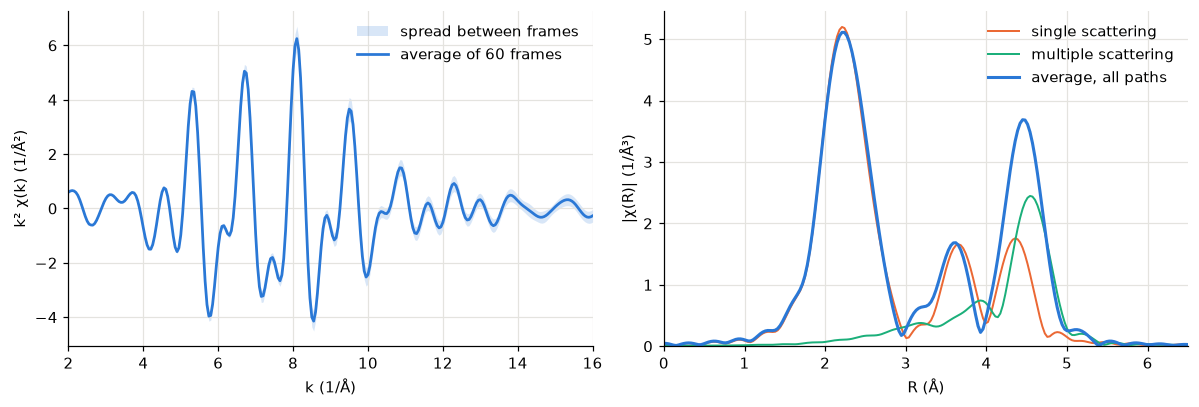

In [7]:
import json
import numpy as np
import matplotlib.pyplot as plt
import torch
from feffgpu.exafs import FitWindow, ft, r_grid, window_tensor

OUT = WORK / "mdexafs_out"
BLUE, ORANGE, AQUA, GRAY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#0b0b0b"
WINDOW = FitWindow(kmin=3.0, kmax=13.0, dk=1.0, kweight=2, rmin=1.0, rmax=5.2)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3df", "legend.frameon": False, "figure.dpi": 110})


def chi_r(k, chi, window=WINDOW):
    """R (Å) and |chi(R)| of a spectrum on the package's k grid, with the package's conventions (xraylarch's)."""
    kt = torch.as_tensor(k, dtype=torch.float64)
    c = ft(torch.as_tensor(chi, dtype=torch.float64)[None], kt, window_tensor(kt, window), window.kweight)[0]
    return r_grid().numpy(), c.abs().numpy()


k, chi, spread, stderr = np.loadtxt(OUT / "average" / "Fe.chi", unpack=True)
header = (OUT / "average" / "Fe.parts.dat").read_text().splitlines()[1]
names = [s.strip() for s in header.split("columns:")[1].split("|")]
parts = dict(zip(names, np.loadtxt(OUT / "average" / "Fe.parts.dat", unpack=True)))
print("parts:", ", ".join(names[1:]))

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8))
a.fill_between(k, k**2 * (chi - spread), k**2 * (chi + spread), color=BLUE, alpha=0.18, lw=0, label="spread between frames")
a.plot(k, k**2 * chi, color=BLUE, lw=1.8, label=f"average of {len(frames)} frames")
a.set(xlim=(2, 16), xlabel="k (1/Å)", ylabel="k² χ(k) (1/Å²)")
a.legend()
for name, color, width in (("single scattering", ORANGE, 1.3), ("multiple scattering", AQUA, 1.3)):
    r, magnitude = chi_r(k, parts[name])
    b.plot(r, magnitude, color=color, lw=width, label=name)
r, magnitude = chi_r(k, chi)
b.plot(r, magnitude, color=BLUE, lw=2.0, label="average, all paths")
b.set(xlim=(0, 6.5), ylim=(0, None), xlabel="R (Å)", ylabel="|χ(R)| (1/Å³)")
b.legend()
fig.tight_layout()

How to read the figure:

- Left: the average, weighted by k². The band is the spread between single frames, each of them the mean over 32
  atoms.
- Right: the magnitude of the Fourier transform. The first peak holds the first two neighbor shells of the bcc
  lattice (8 atoms at 2.48 Å and 6 at 2.87 Å). Peaks of |χ(R)| lie below the real distances, because the scattering
  adds a phase that depends on k.
- The peak near 4.5 Å is mostly multiple scattering. In a bcc lattice the absorbing atom, a first neighbor and the
  atom behind it lie on one line, and scattering through the atom in between is strong. A calculation with single
  scattering only would miss most of this peak.

## 6. Were there enough frames?

`average/average.json` answers with the R-factor. The R-factor of two spectra is the summed squared difference of
their Fourier transforms inside the R window, divided by the summed square of one of them (xraylarch's definition).
Zero means identical; 0.01 is a difference that is easy to see in a figure.

- **R-factor to the final average:** the average of the first n frames against the average of all frames.
- **R-factor between the halves:** the average of the first half of the frames against the average of the second.
  It does not use the final average, so it is the stricter of the two.

R-factor between the two halves of the frames: 4.1e-04


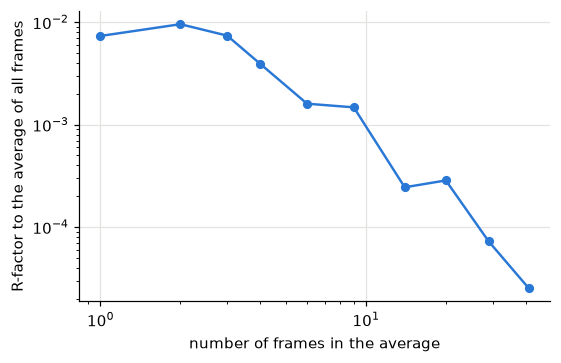

In [8]:
average = json.loads((OUT / "average" / "average.json").read_text())["edges"]["Fe"]
convergence = average["convergence"]
n, to_final = np.array(convergence["n_frames"]), np.array(convergence["r_factor_to_final"])
print(f"R-factor between the two halves of the frames: {convergence['split_half_r_factor']:.1e}")

fig, ax = plt.subplots(figsize=(5.2, 3.4))
ax.loglog(n[:-1], to_final[:-1], "o-", color=BLUE, lw=1.6, ms=5)
ax.set(xlabel="number of frames in the average", ylabel="R-factor to the average of all frames")
fig.tight_layout()

A few tens of frames are enough here, because each frame already averages 32 atoms of a simple crystal. A
disordered or dilute system needs more. The column `stderr` of `Fe.chi` gives the standard error of the average at
every k, from the scatter between blocks of consecutive frames.

## 7. The spectrum and the structure

The structure behind the spectrum is known here, so the numbers that a shell-by-shell fit of a spectrum tries to
find can be counted directly. `md-exafs rdf` computes the radial distribution and, for each `[[rdf.peak]]` of the
configuration, the number of neighbors N, their mean distance R, the variance of the distance σ² (the mean-square
relative displacement) and the third cumulant C3, by counting the distances themselves. Nothing is fitted
([Analysis of trajectories](https://github.com/nmarcella/feffGPU/blob/main/docs/md/analysis.md)).

In [9]:
!md-exafs rdf fe_tutorial/config.toml

RDF of 60 frames (r_max 6.0 A, bins 0.01 A, device cuda)
  6/60 frames (0.2 s)
  12/60 frames (0.2 s)
  18/60 frames (0.2 s)
  24/60 frames (0.3 s)
  30/60 frames (0.3 s)
  36/60 frames (0.3 s)
  42/60 frames (0.4 s)
  48/60 frames (0.4 s)
  54/60 frames (0.4 s)
  60/60 frames (0.5 s)
  Fe-Fe 2-2.68 A: N 7.980, R 2.4843 A, MSRD 0.00506 A^2, C3 8.47e-06 A^3 (integration)
  Fe-Fe 2.68-3.3 A: N 6.020, R 2.8684 A, MSRD 0.00499 A^2, C3 3.78e-05 A^3 (integration)
RDFs in .../tutorials/fe_tutorial/mdexafs_out/rdf


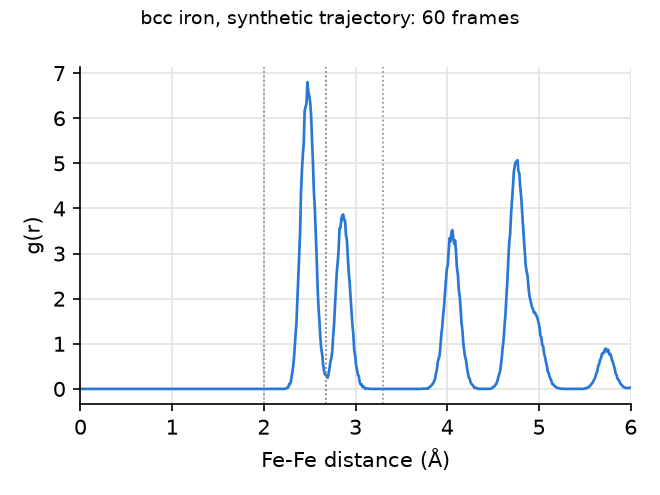

2.00 to 2.68 Å:  N = 7.98   R = 2.484 Å   σ² = 0.0051 Å²   C3 = 8.5e-06 Å³
2.68 to 3.30 Å:  N = 6.02   R = 2.868 Å   σ² = 0.0050 Å²   C3 = 3.8e-05 Å³


In [10]:
from IPython.display import Image, display

display(Image(filename=str(OUT / "rdf" / "rdf.png"), width=460))
for peak in json.loads((OUT / "rdf" / "rdf.json").read_text())["peaks"]:
    v = peak["integration"]
    print(f"{peak['r_min']:.2f} to {peak['r_max']:.2f} Å:  N = {v['N']:.2f}   R = {v['R']:.3f} Å   "
          f"σ² = {v['sigma2']:.4f} Å²   C3 = {v['c3']:.1e} Å³")

N is close to the 8 and 6 of the bcc lattice. It is not exactly 8 and 6 because the two peaks overlap a little at
the boundary of 2.68 Å.

**Parts of the spectrum by path and distance, without a new calculation.** The cache keeps the spectrum of every
frame by kind of path, and for single scattering by distance. The next cell takes from it the single-scattering
signal of the neighbors within 2.68 Å (the first shell) and within 3.3 Å (the first two shells).

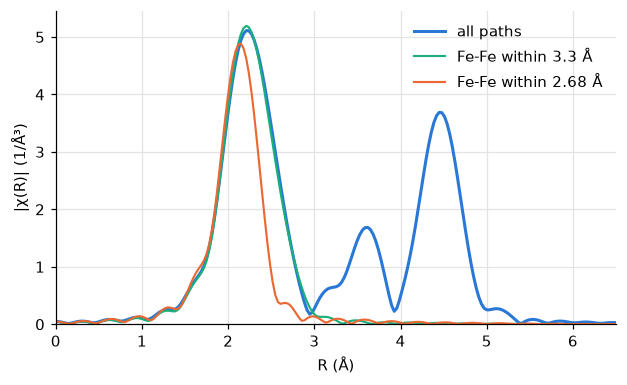

In [11]:
from feffgpu.md import edge_average
from feffgpu.md.cache import open_cache
from feffgpu.md.config import AverageConfig

with open_cache(OUT / "chi.h5") as cache:
    first_shell = edge_average(cache, "Fe", AverageConfig(path_types=["Fe-Fe"], max_distance=2.68, blocks=6))
    two_shells = edge_average(cache, "Fe", AverageConfig(path_types=["Fe-Fe"], max_distance=3.3, blocks=6))

fig, ax = plt.subplots(figsize=(5.8, 3.6))
for label, spectrum, color, width in (("all paths", chi, BLUE, 2.0), ("Fe-Fe within 3.3 Å", two_shells["mean"], AQUA, 1.4),
                                      ("Fe-Fe within 2.68 Å", first_shell["mean"], ORANGE, 1.4)):
    r, magnitude = chi_r(k, np.asarray(spectrum))
    ax.plot(r, magnitude, color=color, lw=width, label=label)
ax.set(xlim=(0, 6.5), ylim=(0, None), xlabel="R (Å)", ylabel="|χ(R)| (1/Å³)")
ax.legend()
fig.tight_layout()

The first peak of |χ(R)| is not the first shell alone: the second shell, only 0.4 Å farther, changes its height and
shape. The same selection is available from the command line: `path_types` and `max_distance` in `[average]`, then
`md-exafs average` ([Path types](https://github.com/nmarcella/feffGPU/blob/main/docs/md/path_types.md)).

## 8. Comparison with a "measured" spectrum

The averaged spectrum of a trajectory is a prediction without a free structural parameter. `md-exafs` compares it
with a measured spectrum as it is and fits only two numbers, both on the calculated spectrum:

- **S0²**, the amplitude factor: one number that scales the whole spectrum;
- **ΔE0**, the shift of the energy origin, in eV.

The misfit is the R-factor inside the window of `[compare]` ([Comparison](https://github.com/nmarcella/feffGPU/blob/main/docs/md/comparison.md)).

The "measured" spectrum of this tutorial is synthetic: the averaged spectrum of a second, independent and ten times
longer trajectory of the same spring model, multiplied by S0² = 0.80, shifted by ΔE0 = +2.0 eV, with a little noise
added. The comparison should find these two numbers again. `md-exafs run` has already made it, because the
configuration has a `[compare]` block; `md-exafs compare fe_tutorial/config.toml` repeats it from the cache.

R-factor: 1.8e-04
S0²: 0.807   (planted 0.80)   interval 0.803 to 0.810   sampling standard error 0.005
ΔE0: 2.08 eV   (planted 2.00)   interval 2.04 to 2.11   sampling standard error 0.02 eV


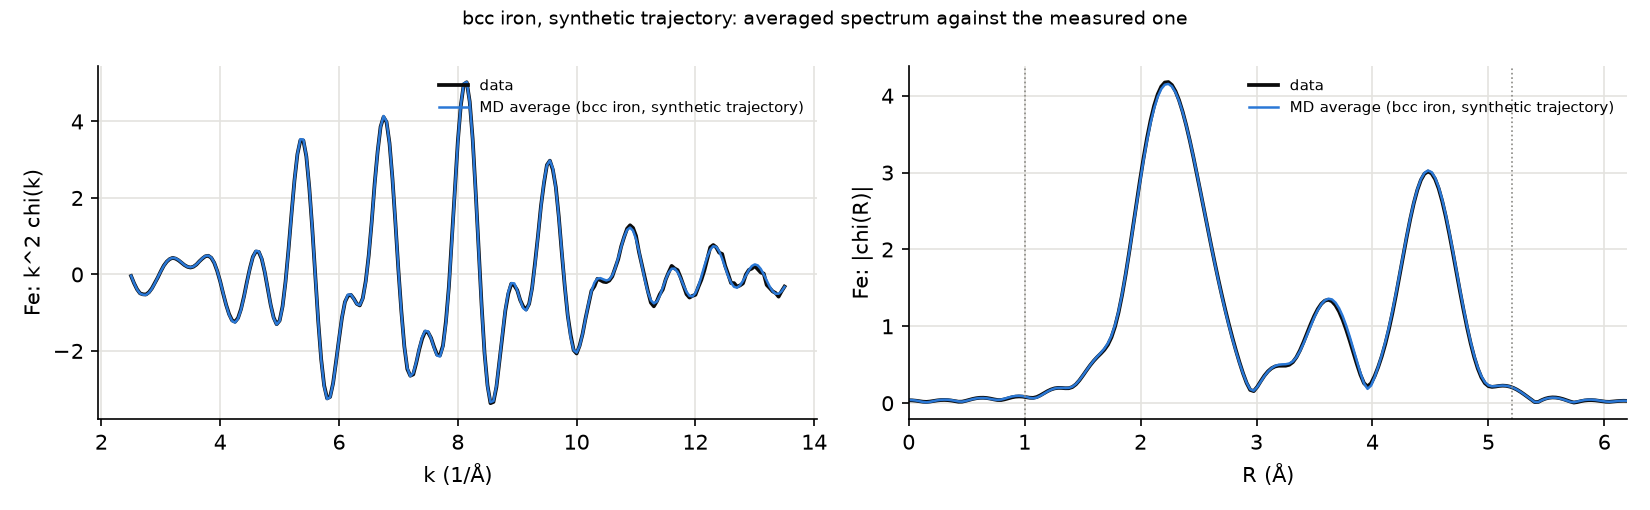

In [12]:
report = json.loads((OUT / "compare" / "compare.json").read_text())
shared, spectrum = report["shared"], report["runs"][0]["spectra"][0]
print(f"R-factor: {spectrum['r_factor']:.1e}")
print(f"S0²: {shared['s02']['Fe']:.3f}   (planted 0.80)   interval {shared['s02_interval']['Fe'][0]:.3f} to "
      f"{shared['s02_interval']['Fe'][1]:.3f}   sampling standard error {shared['sampling']['s02_se']['Fe']:.3f}")
print(f"ΔE0: {shared['de0']['Fe']:.2f} eV   (planted 2.00)   interval {shared['de0_interval']['Fe'][0]:.2f} to "
      f"{shared['de0_interval']['Fe'][1]:.2f}   sampling standard error {shared['sampling']['de0_se']['Fe']:.2f} eV")
display(Image(filename=str(OUT / "compare" / "compare.png"), width=900))

Each fitted number comes with two uncertainties, which answer different questions:

- **The interval** says how well the measured spectrum fixes the number for this averaged spectrum, with the
  structure held fixed (90 %).
- **The sampling standard error** says how much the number would move with another set of frames of the same
  dynamics. It comes from repeating the fit with each block of frames left out.

In the run stored with this notebook, S0² came out as 0.807 with a sampling standard error of 0.005: the planted
0.80 is a little more than one standard error away. ΔE0 came out as 2.08 eV with a sampling standard error of
0.02 eV, so the planted 2.00 eV is farther away than the sampling explains.

The rest comes from the potentials. This run and the synthetic spectrum took the cluster for their potentials from
different snapshots. When this run was repeated with three other choices of the frame and the atom that define
the cluster, ΔE0 came out between 1.95 and 2.08 eV, and S0² between 0.804 and 0.808. For this system the choice of
the reference cluster therefore moves ΔE0 by about 0.1 eV and S0² by less than 0.01. You can see it yourself: add
`reference_frame = 30` and `reference_atom = 64` to the `[[edge]]` block, change `output`, and run again.

## 9. Your own trajectory

The second notebook, [02_md_exafs_your_trajectory.ipynb](https://github.com/nmarcella/feffGPU/blob/main/tutorials/02_md_exafs_your_trajectory.ipynb), runs
the same steps on a file that you upload. What changes in the configuration:

- `[system] trajectory`: your file. For LAMMPS dumps with numeric atom types, an `[atoms]` block maps the types to
  elements.
- `[lattice]`: `dynamic = true` when every frame carries its cell, otherwise the cell lengths and angles.
- `[[edge]]`: your absorbing element and edge; one block per edge. Set `rpath` to the largest distance you want
  to interpret, and keep the cell at least twice as wide.
- `[frames]`: choose frames that are far enough apart in time, after the equilibration.
- `[compare] chi`: your measured chi(k), in two columns (files written by Athena and xraylarch are read as they are).

No trajectory yet? `md-exafs dynamics` makes one with a MACE potential or any ASE calculator
([Dynamics](https://github.com/nmarcella/feffGPU/blob/main/docs/md/dynamics.md)).

When you publish results obtained with this package, cite FEFF and the original MD-EXAFS program
([Citing](https://github.com/nmarcella/feffGPU/blob/main/docs/citing.md)).

### Keep the results (Colab)

Colab deletes the files of a session when it ends. The next cell packs the working folder into one zip file and
downloads it. Outside Colab it does nothing.

In [13]:
if IN_COLAB:
    from google.colab import files
    shutil.make_archive("fe_tutorial_results", "zip", WORK)
    files.download("fe_tutorial_results.zip")